# BT1 – Bias và Variance với hồi quy đa thức

MSHV: 26848249

Bài này em làm lại ví dụ ở trang 58–68 trong slides. Dữ liệu được sinh từ hàm sin (giống trong slides) rồi cộng thêm nhiễu ngẫu nhiên có độ lệch chuẩn 0.03, tức là khá nhỏ. Các giá trị x được lấy ngẫu nhiên trong đoạn từ 0 đến 1.

Em tạo ba bộ dữ liệu D1, D2, D3. Mỗi bộ có một tập train và một tập test, hai tập có cùng số điểm. Với mỗi tập train, em fit 9 đa thức từ bậc 1 đến bậc 9, sau đó tính E_in trên tập train và Ê_out trên tập test. Em chạy thí nghiệm ba lần, lần lượt với 10, 100 và 1000 điểm.

In [1]:
import numpy as np
import random

seed = 26848249
np.random.seed(seed)
random.seed(seed)

import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## Các hàm dùng chung

In [2]:
SIGMA = 0.03                   # độ lệch chuẩn của nhiễu
DEGREES = range(1, 10)         # bậc đa thức 1..9
XG = np.linspace(0, 1, 300)    # các điểm x để vẽ đường cong

# Bậc 9 với 10 điểm làm numpy cảnh báo RankWarning, kết quả vẫn dùng được nên tắt cảnh báo
warnings.simplefilter("ignore", getattr(np, "exceptions", np).RankWarning)


def f(x):
    return np.sin(1 + x ** 2)


def make_split(n):
    # Sinh n điểm: x lấy ngẫu nhiên, y là giá trị của hàm gốc cộng thêm nhiễu
    x = np.random.uniform(0, 1, n)
    y = f(x) + np.random.normal(0, SIGMA, n)
    return x, y


def make_dataset(n):
    # Một bộ dữ liệu gồm tập train và tập test, mỗi tập n điểm
    x_train, y_train = make_split(n)
    x_test, y_test = make_split(n)
    return {"x_train": x_train, "y_train": y_train, "x_test": x_test, "y_test": y_test}


def train_models(D):
    # Huấn luyện 9 đa thức bậc 1..9 trên tập train, trả về hệ số của từng mô hình
    return [np.polyfit(D["x_train"], D["y_train"], d) for d in DEGREES]


def mse(coef, x, y):
    return np.mean((np.polyval(coef, x) - y) ** 2)


def run_experiment(n):
    # Tạo 3 bộ dữ liệu D1, D2, D3 và huấn luyện 9 mô hình trên mỗi bộ
    datasets = [make_dataset(n) for _ in range(3)]
    models = [train_models(D) for D in datasets]
    return datasets, models


def error_table(datasets, models):
    # Bảng E_in, Ê_out của 9 bậc cho D1, D2, D3 (giống trang 66)
    table = {}
    for k, (D, coefs) in enumerate(zip(datasets, models), start=1):
        table[(f"D{k}", "E_in")] = [mse(c, D["x_train"], D["y_train"]) for c in coefs]
        table[(f"D{k}", "Ê_out")] = [mse(c, D["x_test"], D["y_test"]) for c in coefs]
    return pd.DataFrame(table, index=pd.Index(DEGREES, name="Degree"))


def show(df, decimals=5):
    # Hiển thị dạng số thập phân (không dùng số mũ e), có dấu phẩy ngăn cách hàng nghìn
    display(df.apply(lambda col: col.map(lambda v: f"{v:,.{decimals}f}")))


def plot_one(D, coefs, name):
    # 9 hình nhỏ cho 1 bộ dữ liệu, có điểm train/test và E_in, Ê_out ở tiêu đề (giống trang 65)
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharex=True, sharey=True)
    for j, ax in enumerate(axes.flat):
        e_in = mse(coefs[j], D["x_train"], D["y_train"])
        e_out = mse(coefs[j], D["x_test"], D["y_test"])
        ax.plot(XG, f(XG), color="gray", lw=3, alpha=0.7, label="f(x)")
        ax.plot(XG, np.polyval(coefs[j], XG), color="tab:green", lw=1.5, label="đường fit")
        ax.plot(D["x_train"], D["y_train"], "o", color="tab:blue", ms=6, label="train")
        ax.plot(D["x_test"], D["y_test"], "*", color="tab:red", ms=9, label="test")
        ax.set_title(f"degree {j + 1}\nE_in = {e_in:.5f}, Ê_out = {e_out:,.5f}", fontsize=10)
        ax.set_xlim(0, 1)
        ax.set_ylim(0.7, 1.1)
        ax.grid(alpha=0.3)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.965))
    fig.suptitle(f"Bộ dữ liệu {name}, kích thước tập train = {len(D['x_train'])}", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()


def plot_three(models, n):
    # 9 hình nhỏ, mỗi hình là 1 bậc, vẽ 3 đường fit của D1, D2, D3 (giống trang 68)
    colors = ["tab:green", "tab:purple", "tab:orange"]
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharex=True, sharey=True)
    for j, ax in enumerate(axes.flat):
        ax.plot(XG, f(XG), color="gray", lw=3, alpha=0.7, label="f(x)")
        for k in range(3):
            ax.plot(XG, np.polyval(models[k][j], XG), color=colors[k], lw=1.5, label=f"D{k+1}")
        ax.set_title(f"degree {j + 1} polynomials")
        ax.set_xlim(0, 1)
        ax.set_ylim(0.7, 1.1)
        ax.grid(alpha=0.3)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.965))
    fig.suptitle(f"Kích thước tập train = {n}", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()


data, models = {}, {}

## 1. Tập train 10 điểm

In [3]:
data[10], models[10] = run_experiment(10)
show(error_table(data[10], models[10]))

D1                         D2                                 D3  \
           E_in             Ê_out     E_in                     Ê_out     E_in   
Degree                                                                          
1       0.00070           0.00183  0.00121                   0.00231  0.00176   
2       0.00068           0.00197  0.00121                   0.00231  0.00098   
3       0.00050           0.00116  0.00113                   0.00205  0.00051   
4       0.00050           0.00129  0.00112                   0.00156  0.00038   
5       0.00050           0.01423  0.00084                   0.04123  0.00029   
6       0.00046           1.63355  0.00027                   5.63671  0.00027   
7       0.00046           3.74759  0.00027                  37.81825  0.00002   
8       0.00045      22,504.08014  0.00008           8,918,081.46013  0.00000   
9       0.00000  21,184,226.34079  0.00000  60,476,331,015,085.97656  0.00000   

                 
          Ê_out  
Degree           
1       0.00124  
2       0.00056  
3       0.00030  
4       0.00038  
5       0.00042  
6       0.00051  
7       0.00784  
8       0.00656  
9       0.01927

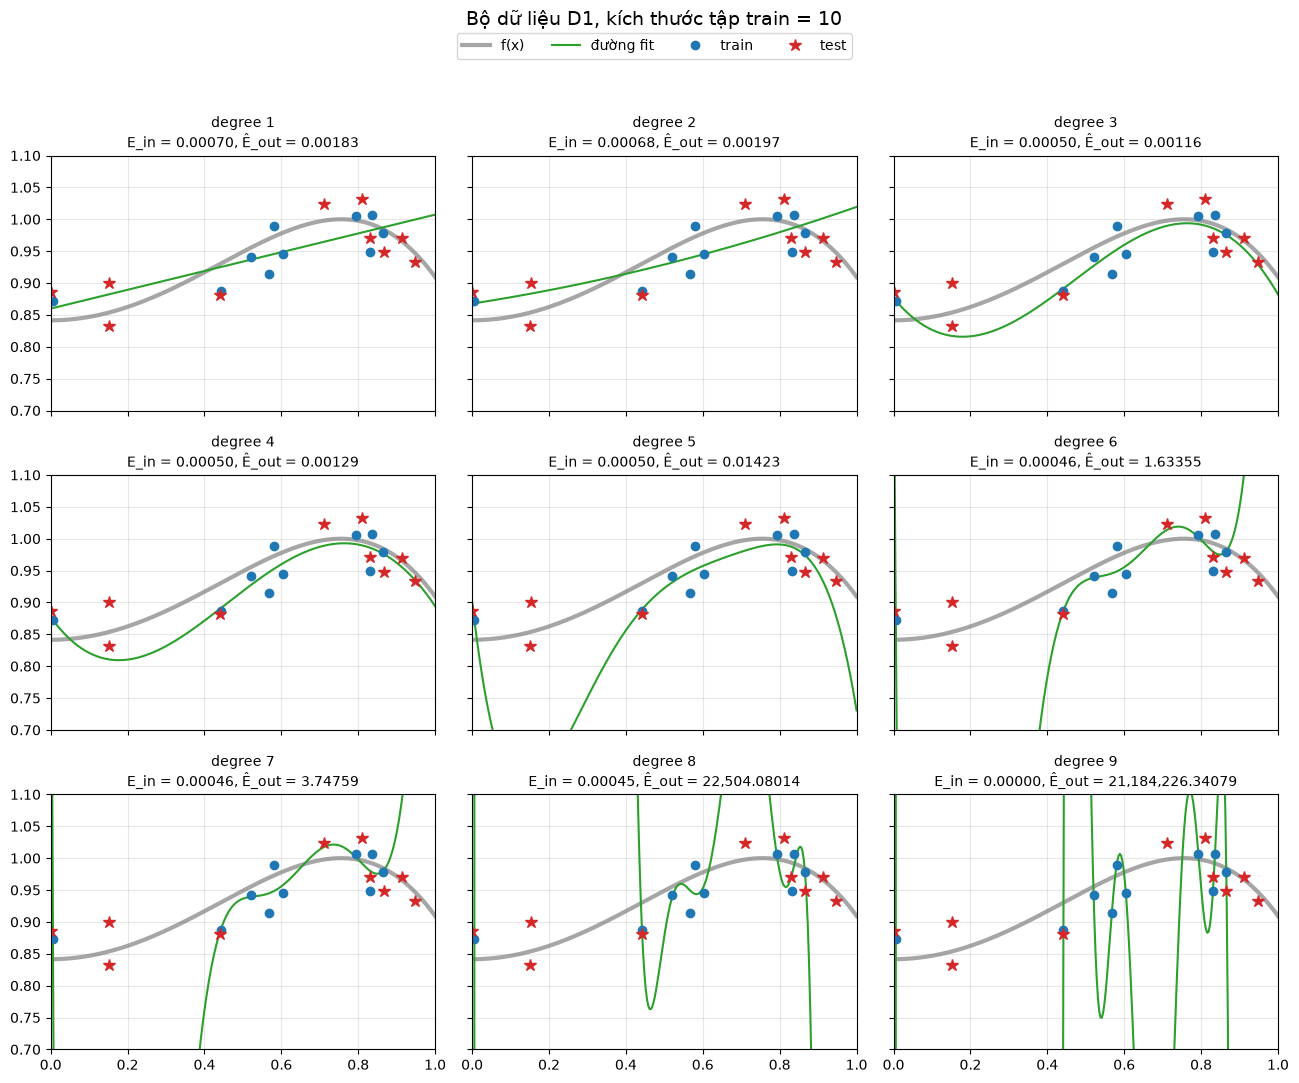

In [4]:
plot_one(data[10][0], models[10][0], "D1")

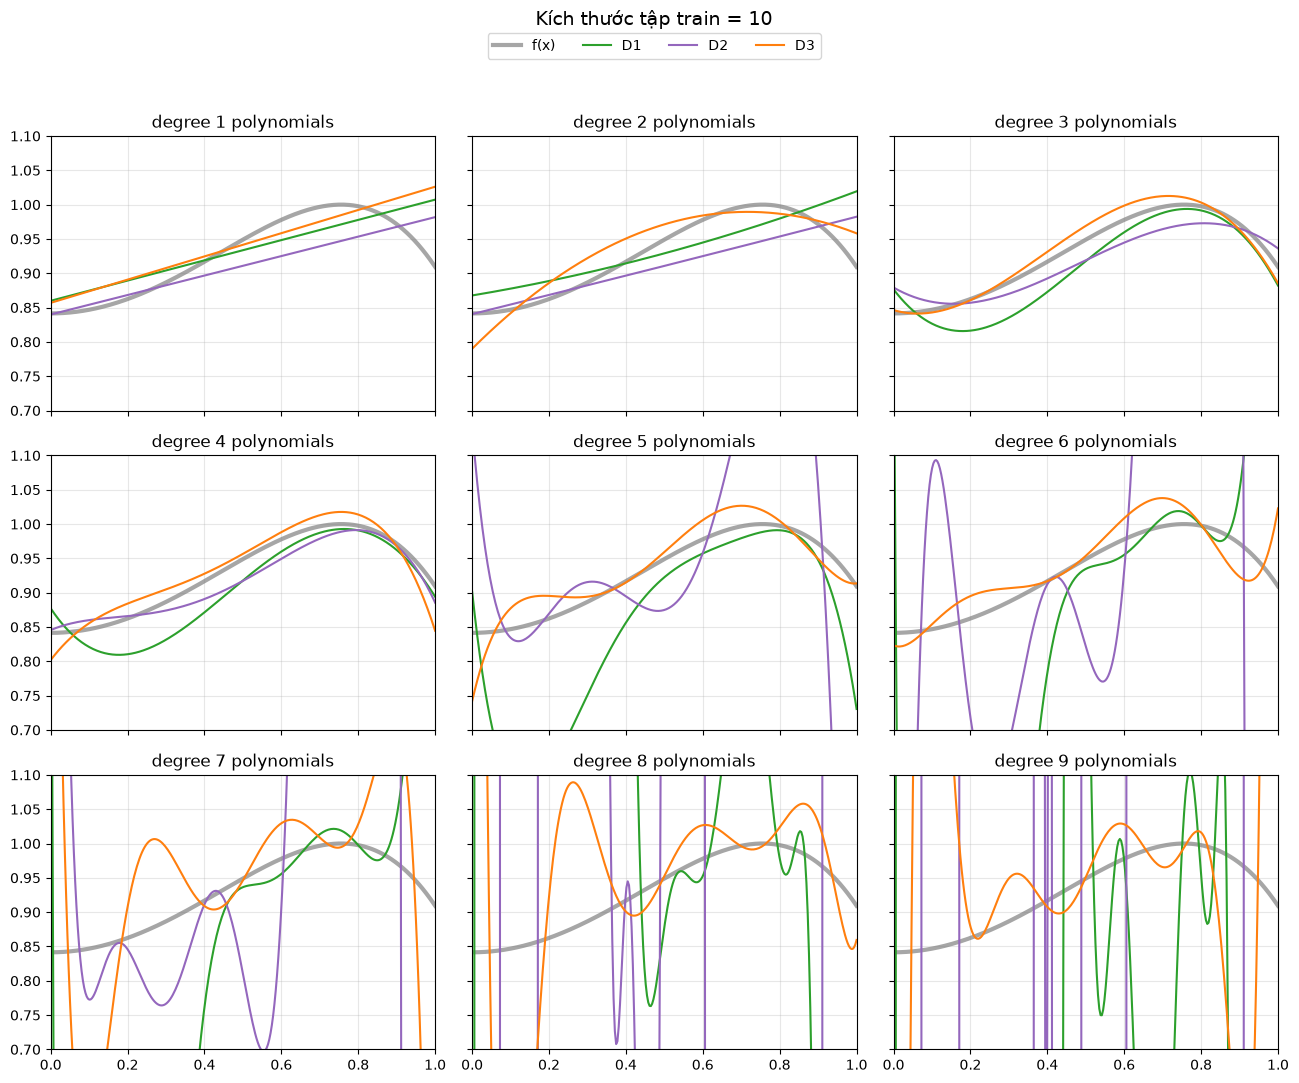

In [5]:
plot_three(models[10], 10)

**Nhận xét với 10 điểm**

Bậc càng cao thì E_in càng nhỏ, và tới bậc 9 thì E_in về 0 luôn. Chuyện này dễ hiểu: đa thức bậc 9 có 10 hệ số, đủ để đi qua cả 10 điểm train, nhiễu cũng học theo luôn.

Ê_out lại không đi theo hướng đó. Từ bậc 1 tới bậc 4 nó vẫn còn nhỏ, cỡ 0.0003 tới 0.0023. Với D1 và D2, sang bậc 5 là Ê_out bắt đầu tăng vọt, đến bậc 9 thì D1 lên khoảng 21 triệu còn D2 lên khoảng 60 nghìn tỷ. D3 thì chịu được lâu hơn: bậc 5 và 6 vẫn chỉ 0.00042 và 0.00051, tới bậc 7 mới nhảy lên 0.0078 và bậc 9 là 0.019. Con số này vẫn lớn hơn các bậc thấp rất nhiều. Bậc overfit bắt đầu lộ ra còn phụ thuộc vào việc 10 điểm rơi vào đâu. Bậc cho Ê_out nhỏ nhất ở D1, D2, D3 là 3, 4 và 3, khá khớp với bảng ở trang 66.

Hình đầu tiên (chỉ có D1, kèm điểm train và test) cho thấy rõ cách overfit xảy ra. Ở bậc 9, đường fit đi qua đúng cả 10 chấm xanh nên E_in bằng 0, nhưng giữa các chấm nó uốn lên xuống dữ dội và trượt gần hết các ngôi sao đỏ. Tập train của D1 lại gần như không có điểm nào trong khoảng từ 0 đến 0.44 (chỉ có một điểm sát 0). Từ bậc 5 trở lên, đường fit lao ra khỏi khung hình đúng ở khoảng trống này, vì không có điểm nào giữ nó lại. Ngay cả bậc 3 và 4 cũng bị võng xuống quanh x khoảng 0.2, thấp hơn hàm gốc. Có thể thấy với ít điểm, mô hình phụ thuộc rất nhiều vào việc các điểm rơi vào đâu.

Hình thứ hai chồng 3 bộ D1, D2, D3 lên nhau nên thấy rõ hơn chuyện bias và variance. Ở bậc 1 và 2, ba đường gần như giống nhau nên variance thấp, nhưng đường nào cũng không uốn theo được chỗ đỉnh của hàm gốc (quanh x khoảng 0.75) và lệch khá xa ở gần đầu bên phải. Nghĩa là bias cao, mô hình bị underfit.

Bậc 3 và 4 thì ổn nhất: đường fit bám khá sát hàm gốc mà ba bộ dữ liệu cũng cho ra kết quả không khác nhau mấy. Với chỉ 10 điểm, em thấy đây là lựa chọn hợp lý.

Từ bậc 5 trở đi, các đường bắt đầu tách nhau ra, uốn lượn mạnh và văng ra ngoài khung hình, nhất là ở hai đầu. Đường của D3 giữ được hình dạng lâu hơn, nhưng tới bậc 7–9 thì cũng lệch hẳn khỏi hai đường kia. Mô hình đủ linh hoạt nên bias thấp, nhưng variance thì rất cao. Đây là overfit.

## 2. Tập train 100 điểm

In [6]:
data[100], models[100] = run_experiment(100)
show(error_table(data[100], models[100]))

D1                D2                D3         
           E_in    Ê_out     E_in    Ê_out     E_in    Ê_out
Degree                                                      
1       0.00148  0.00147  0.00111  0.00139  0.00184  0.00216
2       0.00131  0.00113  0.00085  0.00109  0.00156  0.00163
3       0.00106  0.00092  0.00073  0.00091  0.00098  0.00116
4       0.00101  0.00101  0.00073  0.00092  0.00097  0.00114
5       0.00101  0.00101  0.00073  0.00093  0.00096  0.00116
6       0.00100  0.00102  0.00072  0.00093  0.00095  0.00112
7       0.00098  0.00108  0.00072  0.00094  0.00095  0.00111
8       0.00095  0.00110  0.00072  0.00094  0.00094  0.00112
9       0.00094  0.00114  0.00072  0.00094  0.00094  0.00112

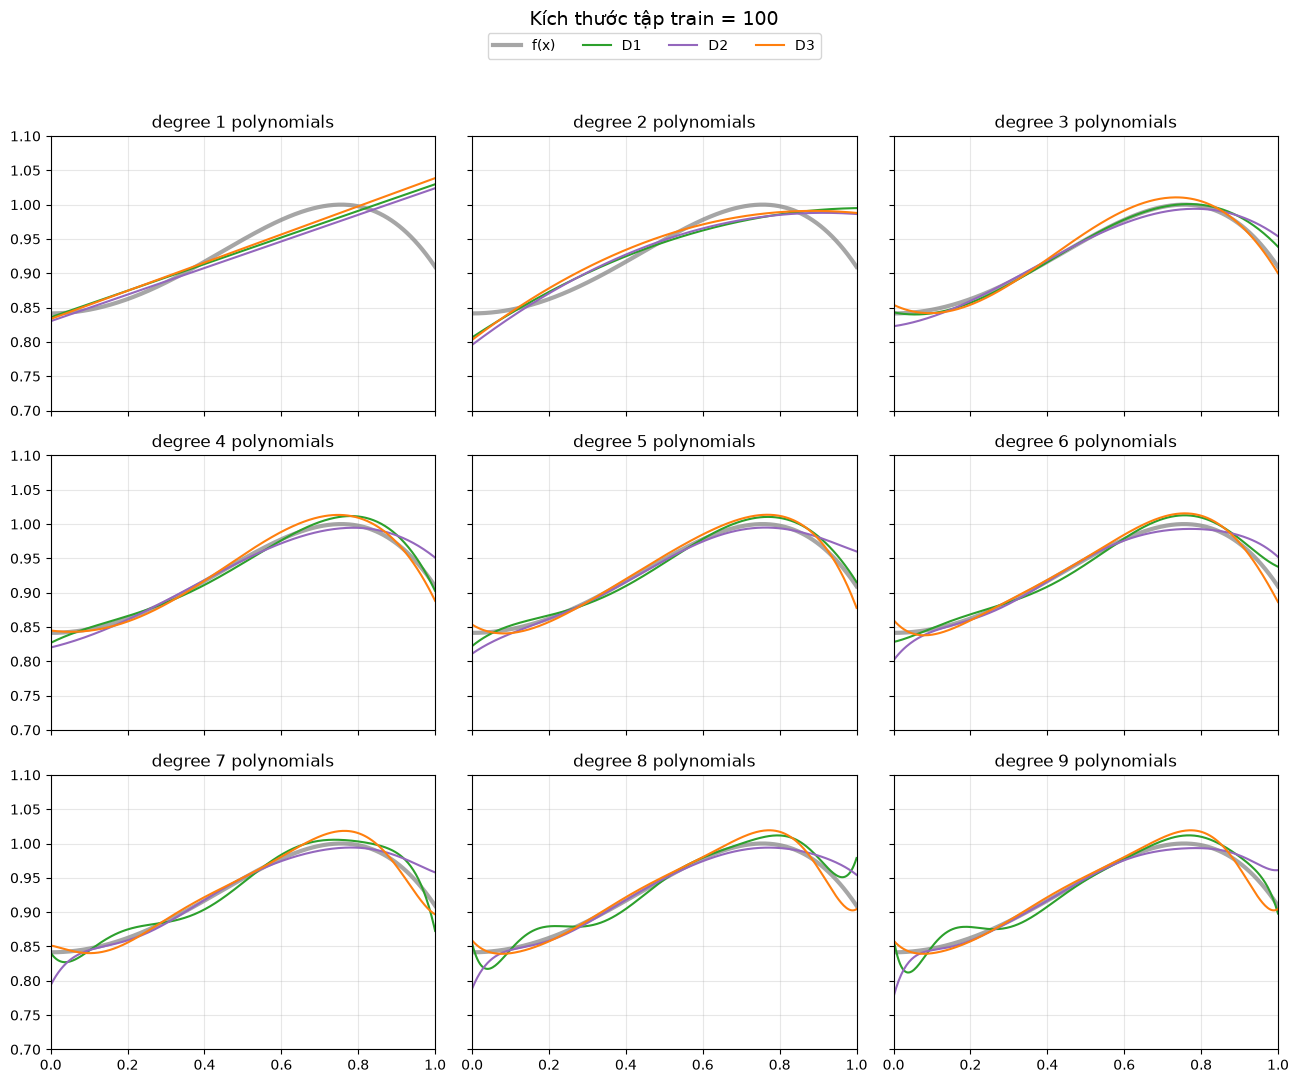

In [7]:
plot_three(models[100], 100)

**Nhận xét với 100 điểm**

Lúc này E_in và Ê_out ở bậc nào cũng khá gần nhau. Bậc 9 không còn E_in bằng 0 nữa (khoảng 0.00072 tới 0.00094), còn Ê_out chỉ quanh 0.001, không còn bùng lên như lúc chỉ có 10 điểm.

Bậc 1 và 2 vẫn có Ê_out cao hơn phần còn lại. Lấy trung bình ba bộ thì hai bậc này được 0.00167 và 0.00129, trong khi từ bậc 3 trở lên chỉ khoảng 0.0010.

Trên hình, ba đường của cùng một bậc gần như chồng lên nhau. Bậc 1 và 2 vẫn lệch khỏi hàm gốc y như trước, tức là bias vẫn còn đó. Bậc 7 tới 9 chỉ còn hơi rung ở hai đầu, variance đã giảm đi nhiều.

## 3. Tập train 1000 điểm

In [8]:
data[1000], models[1000] = run_experiment(1000)
show(error_table(data[1000], models[1000]))

D1                D2                D3         
           E_in    Ê_out     E_in    Ê_out     E_in    Ê_out
Degree                                                      
1       0.00142  0.00165  0.00159  0.00154  0.00169  0.00168
2       0.00110  0.00122  0.00112  0.00117  0.00123  0.00120
3       0.00085  0.00089  0.00080  0.00083  0.00089  0.00088
4       0.00083  0.00088  0.00079  0.00082  0.00088  0.00088
5       0.00083  0.00088  0.00079  0.00082  0.00088  0.00088
6       0.00083  0.00088  0.00079  0.00082  0.00088  0.00088
7       0.00083  0.00088  0.00079  0.00082  0.00088  0.00088
8       0.00083  0.00088  0.00079  0.00083  0.00088  0.00088
9       0.00083  0.00088  0.00079  0.00083  0.00088  0.00088

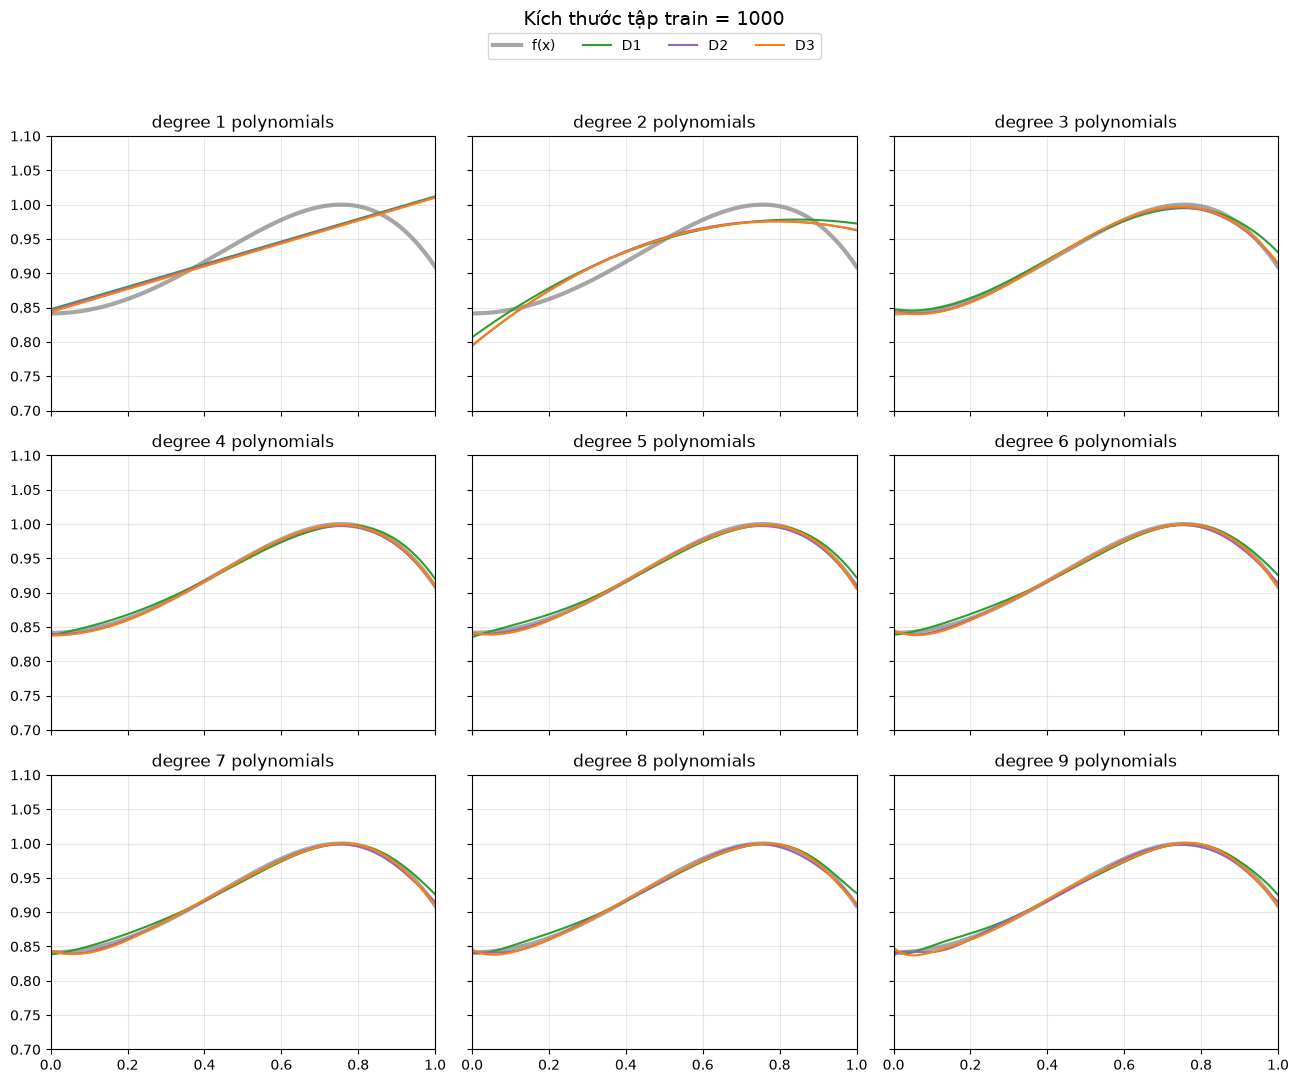

In [9]:
plot_three(models[1000], 1000)

**Nhận xét với 1000 điểm**

E_in và Ê_out bây giờ gần như bằng nhau. Từ bậc 3 trở lên, Ê_out chỉ còn khoảng 0.00082 tới 0.00089, xấp xỉ đúng mức nhiễu em đã cộng vào lúc tạo dữ liệu (độ lệch chuẩn 0.03, tức phương sai khoảng 0.0009). Thấp hơn mức này thì gần như không thể, vì nhiễu là ngẫu nhiên, mô hình nào cũng không đoán trước được.

Bậc 1 (Ê_out khoảng 0.0015 tới 0.0017) và bậc 2 (khoảng 0.0012) vẫn cao hơn thấy rõ.

Trên hình, ba đường ở bậc nào cũng gần như trùng khít, variance coi như không còn. Có điều bậc 1 vẫn chỉ là một đường thẳng nằm lệch khỏi hàm gốc. Dữ liệu đã lên tới 1000 điểm mà bias của nó vẫn không thay đổi.

## 4. So sánh khi tăng kích thước tập train

Để trả lời hai câu hỏi của bài, em tính thêm hai con số cho mỗi bậc:

- **Độ lệch so với hàm gốc**: em lấy trung bình của các đường fit, rồi xem đường trung bình này cách hàm gốc bao xa trên cả đoạn từ 0 đến 1. Con số này đại diện cho bias.
- **Độ phân tán**: em xem các đường fit khác nhau nhiều hay ít, cũng tính trung bình trên cả đoạn. Con số này đại diện cho variance.

Nếu chỉ dùng 3 bộ D1, D2, D3 thì hai con số này dao động khá nhiều. Ngoài ra độ lệch còn bị cộng thêm khoảng một phần ba độ phân tán, vì trung bình của 3 đường vẫn còn rung theo dữ liệu. Vì vậy ở phần này em sinh thêm 200 bộ dữ liệu mới cho mỗi kích thước, vẫn đúng cách sinh và cùng kích thước train/test như trước. Hình và bảng ở các mục 1–3 vẫn dùng 3 bộ D1, D2, D3. Do 200 bộ mới được sinh sau nên các kết quả đó không thay đổi.

Em cũng kiểm tra lại cách tính bằng cách cộng bias, variance và mức nhiễu rồi so với Ê_out trung bình. Theo lý thuyết, hai bên phải xấp xỉ bằng nhau.

In [10]:
K = 200   # số bộ dữ liệu dùng để ước lượng bias và variance


def bias_and_variance(model_list):
    curves = np.array([[np.polyval(c, XG) for c in coefs] for coefs in model_list])   # (số bộ, 9 bậc, 300 điểm)
    bias2 = ((curves.mean(axis=0) - f(XG)) ** 2).mean(axis=1)
    variance = curves.var(axis=0, ddof=1).mean(axis=1)
    return bias2, variance


sizes = [10, 100, 1000]
idx = pd.Index(DEGREES, name="Degree")
bias_df, var_df, eout_df, eout_med_df, check_df = (pd.DataFrame(index=idx) for _ in range(5))
for n in sizes:
    # Sinh thêm K bộ dữ liệu mới (sau 3 bộ D1, D2, D3 nên không ảnh hưởng kết quả ở trên)
    sets = [make_dataset(n) for _ in range(K)]
    fits = [train_models(D) for D in sets]
    b, v = bias_and_variance(fits)
    errs = np.array([[mse(c, D["x_test"], D["y_test"]) for c in coefs] for D, coefs in zip(sets, fits)])
    eout = errs.mean(axis=0)
    bias_df[f"n = {n}"] = b
    var_df[f"n = {n}"] = v
    eout_df[f"n = {n}"] = eout
    eout_med_df[f"n = {n}"] = np.median(errs, axis=0)
    check_df[f"n = {n}"] = (b + v + SIGMA ** 2) / eout

print(f"Ê_out trung bình của {K} bộ:")
show(eout_df, decimals=8)
print(f"Ê_out trung vị của {K} bộ (ít bị ảnh hưởng bởi vài bộ văng cực xa):")
show(eout_med_df, decimals=8)
print("Độ lệch của đường trung bình so với f (bias):")
show(bias_df, decimals=8)
print("Độ phân tán giữa các mô hình (variance):")
show(var_df, decimals=8)
print("Kiểm tra: (bias + variance + nhiễu) / Ê_out, càng gần 1 càng khớp")
show(check_df, decimals=3)

Ê_out trung bình của 200 bộ:


,n = 10,n = 100,n = 1000
Degree,,,
1,0.00231193,0.00172805,0.00168641
2,0.00271491,0.00130586,0.00125706
3,0.00864977,0.00096080,0.00090832
4,0.05463296,0.00095891,0.00090309
5,11.97414029,0.00096867,0.00090407
6,693.23347070,0.00098251,0.00090500
7,"89,870.43083301",0.00099843,0.00090595
8,"18,290,573.60266708",0.00100938,0.00090688
9,"1,260,248,291,381.48510742",0.00105360,0.00090766


Ê_out trung vị của 200 bộ (ít bị ảnh hưởng bởi vài bộ văng cực xa):


,n = 10,n = 100,n = 1000
Degree,,,
1,0.00200890,0.00172662,0.00168387
2,0.00166203,0.00129881,0.00125712
3,0.00152013,0.00095428,0.00090901
4,0.00180588,0.00095073,0.00090258
5,0.00339239,0.00095543,0.00090276
6,0.01015906,0.00097438,0.00090411
7,0.17122018,0.00099004,0.00090542
8,5.58645516,0.00100980,0.00090682
9,"1,023.58767091",0.00102255,0.00090778


Độ lệch của đường trung bình so với f (bias):


,n = 10,n = 100,n = 1000
Degree,,,
1,0.00080713,0.00079701,0.00079705
2,0.00045397,0.00036336,0.00036285
3,0.00005056,0.00000643,0.00000637
4,0.00036556,0.00000011,0.00000007
5,0.01722889,0.00000017,0.00000007
6,10.24110995,0.00000023,0.00000006
7,"2,761.83950332",0.00000026,0.00000008
8,"114,315.54632020",0.00000019,0.00000008
9,"5,571,338,622.56247807",0.00000037,0.00000010


Độ phân tán giữa các mô hình (variance):


,n = 10,n = 100,n = 1000
Degree,,,
1,0.00055839,0.00004204,0.00000341
2,0.00120588,0.00004646,0.00000396
3,0.00960965,0.00003934,0.00000372
4,0.09763316,0.00004914,0.00000474
5,19.19286625,0.00005939,0.00000562
6,"1,189.17930981",0.00007265,0.00000666
7,"301,556.04146363",0.00008682,0.00000764
8,"15,359,811.86338664",0.00009973,0.00000863
9,"969,850,658,008.46252441",0.00014038,0.00000949


Kiểm tra: (bias + variance + nhiễu) / Ê_out, càng gần 1 càng khớp


,n = 10,n = 100,n = 1000
Degree,,,
1,0.980,1.006,1.008
2,0.943,1.003,1.008
3,1.221,0.984,1.002
4,1.810,0.990,1.002
5,1.604,0.991,1.002
6,1.730,0.990,1.002
7,3.386,0.989,1.002
8,0.846,0.991,1.002
9,0.774,0.988,1.002


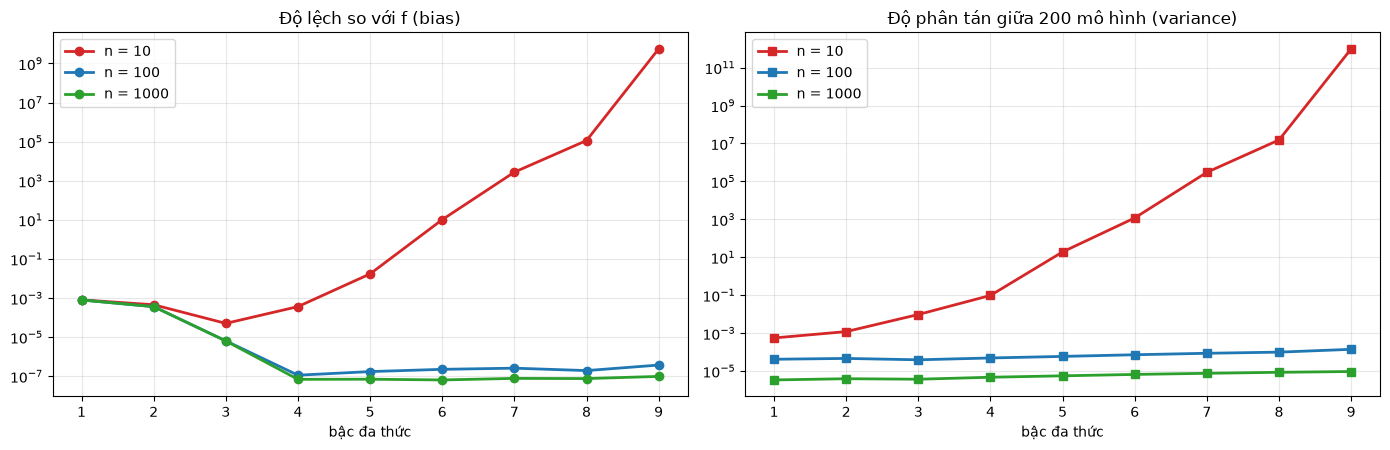

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for n, color in zip(sizes, ["tab:red", "tab:blue", "tab:green"]):
    axes[0].plot(DEGREES, bias_df[f"n = {n}"], "o-", color=color, lw=2, label=f"n = {n}")
    axes[1].plot(DEGREES, var_df[f"n = {n}"], "s-", color=color, lw=2, label=f"n = {n}")
axes[0].set_title("Độ lệch so với f (bias)")
axes[1].set_title(f"Độ phân tán giữa {K} mô hình (variance)")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("bậc đa thức")
    ax.set_xticks(list(DEGREES))
    ax.grid(alpha=0.3, which="both")
    ax.legend()
fig.tight_layout()
plt.show()

## 5. Trả lời câu hỏi

Trước hết là phần kiểm tra. Với 100 và 1000 điểm, tỉ lệ giữa (bias + variance + nhiễu) và Ê_out ở mọi bậc đều nằm trong khoảng 0.98 tới 1.01. Như vậy hai con số bias và variance ở trên đã tính đúng. Với 10 điểm, tỉ lệ này lệch nhiều từ bậc 3 trở lên. Lý do là ở mức này lỗi bị chi phối bởi vài bộ dữ liệu có đường fit văng cực xa, nên trung bình 200 bộ vẫn chưa ổn định, và Ê_out chỉ được tính trên 10 điểm test. Vì vậy với 10 điểm, em chỉ dựa vào các bậc thấp và xu hướng chung.

**Tăng kích thước tập train có giảm được bias không?**

Không. Bậc 1 là ví dụ rõ nhất: độ lệch so với hàm gốc là 0.00081 với 10 điểm, 0.00080 với 100 điểm và 0.00080 với 1000 điểm, gần như đứng yên. Ê_out trung bình của bậc 1 cũng chỉ giảm từ 0.0023 xuống khoảng 0.0017 rồi dừng ở đó, và lúc nào cũng cao hơn các bậc từ 3 trở lên.

Bậc 2 cũng vậy. Độ lệch là 0.00045 với 10 điểm, rồi 0.00036 với cả 100 và 1000 điểm. Từ 100 lên 1000 điểm, con số này giữ nguyên tới chữ số thứ tư. Đi từ 10 lên 100 điểm thì có giảm chút ít. Em nghĩ là vì 10 điểm quá ít nên đường fit trung bình chưa phải là đường bậc 2 tốt nhất có thể. Còn khi dữ liệu đã đủ, có thêm bao nhiêu cũng không kéo được bias xuống thấp hơn.

Ở hình 1000 điểm, ba đường bậc 1 trùng nhau nhưng vẫn là một đường thẳng, không thể đi theo hình dạng của hàm gốc. Như vậy bias phụ thuộc vào việc mô hình có đủ linh hoạt hay không, chứ thêm dữ liệu thì không giải quyết được. Muốn giảm bias thì phải tăng bậc. Ví dụ với 1000 điểm, đổi từ bậc 1 lên bậc 3 là độ lệch giảm từ 0.00080 xuống còn 0.0000064.

Có một điểm cần lưu ý: ở bảng độ lệch với 10 điểm, bậc 4 lại có độ lệch cao hơn bậc 3, và từ bậc 5 trở lên con số tăng vọt, đến bậc 9 lên tới hàng tỷ. Đó không phải bias thật. Các đường fit dao động quá mạnh nên đường trung bình của chúng cũng bị kéo lệch theo. Thực chất đây là ảnh hưởng của variance.

**Tăng kích thước tập train có giảm được variance không?**

Có, và giảm rất rõ. Độ phân tán giữa các mô hình khi đi từ 10 lên 100 rồi 1000 điểm:

- bậc 1: 0.00056, rồi 0.000042, rồi 0.0000034
- bậc 3: 0.0096, rồi 0.000039, rồi 0.0000037
- bậc 9: khoảng 970 tỷ, rồi 0.00014, rồi 0.0000095

Từ 100 lên 1000 điểm, variance ở bậc nào cũng giảm khoảng 10 tới 15 lần, gần đúng bằng mức tăng của dữ liệu. Ở ba hình 3×3 cũng thấy được điều này: càng nhiều điểm thì các đường của D1, D2, D3 càng sát nhau. Bậc 9 lúc có 10 điểm thì dao động lung tung, đến 1000 điểm thì gần như nằm trùng lên hàm gốc. Ê_out trung bình của bậc 9 cũng giảm từ khoảng 1.3 nghìn tỷ xuống 0.0011, rồi còn 0.00091. Con số cuối gần sát mức nhiễu 0.0009.

Em nghĩ lý do là khi có nhiều điểm hơn thì nhiễu bị triệt tiêu bớt khi lấy trung bình, và các điểm phủ kín cả đoạn từ 0 đến 1, nên mô hình ít bị phụ thuộc vào việc lần này lấy trúng những điểm nào.

**Với 10 điểm thì nên chọn bậc mấy?**

Ở mục 1, với 3 bộ D1, D2, D3 thì bậc tốt nhất là 3 hoặc 4. Nhưng khi chạy 200 bộ, kết quả có khác một chút. Nếu xét trung vị, tức là trường hợp "bình thường", bậc 3 vẫn tốt nhất (khoảng 0.0015), tiếp theo là bậc 2 (0.0017). Nếu xét trung bình thì bậc 1 lại thấp nhất (0.0023), còn bậc 3 đã lên 0.0086 và bậc 4 lên 0.055. Hai cách xét lệch nhau như vậy vì với chỉ 10 điểm, thỉnh thoảng có bộ dữ liệu làm đường bậc 3–4 văng xa ở hai đầu, kéo trung bình lên. Nói cách khác, với 10 điểm thì ngay cả bậc 3–4 cũng đã bắt đầu có variance đáng kể. Bậc 2–3 là lựa chọn an toàn hơn.

## Kết luận

Mô hình đơn giản như bậc 1, 2 có bias cao nhưng variance thấp. Mô hình bậc cao thì ngược lại, bias thấp nhưng variance rất cao khi dữ liệu ít.

Thêm dữ liệu giúp giảm variance, còn bias thì không.

Vì thế khi dữ liệu ít, nên chọn mô hình vừa phải (với 10 điểm thì khoảng bậc 2–3). Khi dữ liệu nhiều rồi thì có thể dùng mô hình phức tạp hơn mà không sợ overfit.